### Comportamiento del valor umbral en el estimulo de corriente para activar un disparo de potencial de acción 
Se emplea un algorimo de busqueda binaria para localizar el valor umbral de disparo a diferentes temperaturas y se puede variar el valor de  A y B. 

Es decir se puede estudiar el efecto de la temperatura tanto en las tasas de transición como en las conductancias 

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate as integrate
import ipywidgets as pw

In [14]:
Cm = 1.0  #Potencial de la membrana 
Vk, VNa, VL = -77.0, 50.0, -54.387  #Potenciales de Nerst 

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate as integrate
import ipywidgets as pw

# 1. Parámetros globales fisiológicos
Cm = 1.0
Vk, VNa, VL = -77.0, 50.0, -54.387

# Conductancias modificadas 
def conductances(A, B, T):
    fact = A * (1 + B * (T - 6.3))
    gk = 36.0 * fact
    gNa = 120.0 * fact #Factor eta multiplicando a las conductancias
    gL = 0.3*fact
    return gk, gNa, gL

# 2. Factor Térmico
def temp(T): 
    return 3.0 ** ((T - 6.3) / 10.0)

# 3. Funciones de Transición con valores experimentales de HH
def alpha_n(V_rel, phi): return phi * (0.01 * (10.0 - V_rel) / (np.exp(1.0 - 0.1 * V_rel) - 1.0 + 1e-9))
def beta_n(V_rel, phi): return phi * (0.125 * np.exp(-V_rel / 80.0))
def alpha_m(V_rel, phi): return phi * (0.1 * (25.0 - V_rel) / (np.exp(2.5 - 0.1 * V_rel) - 1.0 + 1e-9))
def beta_m(V_rel, phi): return phi * (4.0 * np.exp(-V_rel / 18.0))
def alpha_h(V_rel, phi): return phi * (0.07 * np.exp(-V_rel / 20.0))
def beta_h(V_rel, phi): return phi * (1.0 / (np.exp(3.0 - 0.1 * V_rel) + 1.0))
#Valores en el equlibrio t en infinito 
def n_inf(V_rel, phi): return alpha_n(V_rel, phi) / (alpha_n(V_rel, phi) + beta_n(V_rel, phi))
def m_inf(V_rel, phi): return alpha_m(V_rel, phi) / (alpha_m(V_rel, phi) + beta_m(V_rel, phi))
def h_inf(V_rel, phi): return alpha_h(V_rel, phi) / (alpha_h(V_rel, phi) + beta_h(V_rel, phi))

# 4. Estímulo Eléctrico
def Id_tvar(t, pul, delt):
    if 10.0 <= t <= 10.0 + delt:#Se suma el dt para ajustar la duración del pulso 
        return pul
    else:
        return 0.0

# 5. Integrador Principal
def CalcDeriv(y, t, phi, pul, V_rest, dt_pulso, gk, gNa, gL):
    dy = np.zeros(4)
    
    Vm, n, m, h = y
    #Corrientes de paso en cada canal 
    IK = gk * (n**4) * (Vm - Vk) 
    INa = gNa * (m**3) * h * (Vm - VNa)
    IL = gL * (Vm - VL)
    V_rel = Vm - V_rest
    # Estas se integraran 
    dy[0] = (Id_tvar(t, pul, dt_pulso) - IK - INa - IL) / Cm #Ecuación principal de la memabran 
    #Ecuaciones para las variables aleatorias 
    dy[1] = alpha_n(V_rel, phi) * (1.0 - n) - beta_n(V_rel, phi) * n 
    dy[2] = alpha_m(V_rel, phi) * (1.0 - m) - beta_m(V_rel, phi) * m
    dy[3] = alpha_h(V_rel, phi) * (1.0 - h) - beta_h(V_rel, phi) * h
    return dy   
    
# Generar pulso
def pulso(tc, pul, dp, A, B):
    # Se calcula el factor phi para insluir efectos de Temperatura 
    phi = temp(tc)
    V_rest = -65.0
    Vm_0 = -65.0
    V_rel_0 = Vm_0 - V_rest
    
    # Se calculan las conductancias dependientes de la temperatura 
    gk, gNa, gL = conductances(A, B, tc)
    
    Y0 = np.array([Vm_0, n_inf(V_rel_0, phi), m_inf(V_rel_0, phi), h_inf(V_rel_0, phi)]) #Valores inciales
    T1 = np.linspace(0, 50, 10000) 
    #hmax controla la resolución  ya que establece el paso de integración máximo permitido
    Vy = integrate.odeint(CalcDeriv, Y0, T1, args=(phi, pul, V_rest, dp, gk, gNa, gL), hmax=0.05) #Integración #0.05  mejorar en caso de ser necesario||| 
    Sol1 = Vy.T
    return Sol1

#ALgoritmo de busqueda binaria     
def encontrar_umbral_termico(T,dt,A,B):
    
    pul_piso = 0.0      
    pul_techo = 1000   
    tolerancia = 0.001   
    while (pul_techo-pul_piso) > tolerancia:
        
        # Busqueda binaria
        pul_prueba = (pul_techo+pul_piso) / 2.0
        pul_res = pulso(T, pul_prueba,dt,A,B)
        maximo = np.max(pul_res[0])
        
        if maximo >= -15:
            pul_techo = pul_prueba
        else:
            pul_piso = pul_prueba
            
   
    return pul_techo

In [16]:
#Calculo de los 4 valores reportados en el paper 
T_0 = np.linspace(0, 25, 70)
dt = 1
a = 4
b = 0.061
umbral_1 = []
for i in T_0:
    umbral_1.append(encontrar_umbral_termico(i,dt,1,0))
umbral_2 = []
for i in T_0:
    umbral_2.append(encontrar_umbral_termico(i,1,1,0.061))
umbral_3 = []
for i in T_0:
    umbral_3.append(encontrar_umbral_termico(i,1,4,0))
umbral_4 = []
for i in T_0:
    umbral_4.append(encontrar_umbral_termico(i,1,4,0.061))

<>:12: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:12: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
C:\Users\barto\AppData\Local\Temp\ipykernel_3492\694113075.py:12: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  plt.ylabel('Corriente ($\mu A/cm^2$)')


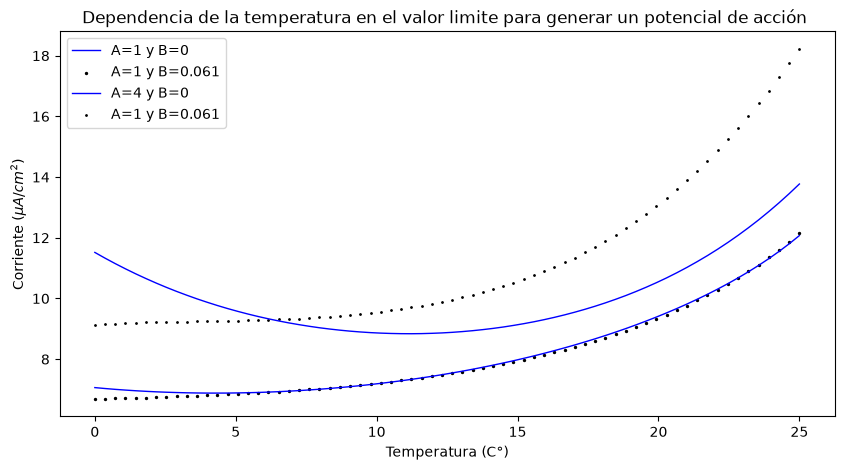

In [17]:
plt.figure(figsize=(10, 5))
plt.plot(T_0, umbral_1, color='blue', linewidth=  1, label = "A=1 y B=0")
plt.scatter(T_0, umbral_2, color='black', s = 2, label = "A=1 y B=0.061")
plt.plot(T_0, umbral_3, color='blue', linewidth=  1, label = "A=4 y B=0")
plt.scatter(T_0, umbral_4, color='black', s =  1, label = "A=1 y B=0.061")
# plt.scatter(T_0, umbral_4, color='k', s = 2.5, label = "Duración del pulso 10 ms")
# plt.scatter(T_0, umbral_2, color='blue', s = 2.5, label = "Duración del pulso 0.5 ms")
# plt.scatter(T_5, umbral_5, color='red', s = 2)
plt.title(f'Dependencia de la temperatura en el valor limite para generar un potencial de acción ')
plt.legend()
plt.xlabel('Temperatura (C°)')
plt.ylabel('Corriente ($\mu A/cm^2$)')
plt.savefig("Sdjin_results.png")